# Links de estudos

- [Link para distribuição uniform do TF]("https://www.tensorflow.org/api_docs/python/tf/random/uniform")
- [Link para o dataset]("https://github.com/sayibet/fight-detection-surv-dataset")
- [Xception Pre-treined TF]("https://www.tensorflow.org/api_docs/python/tf/keras/applications/xception/Xception")
- [Feature Extraction TF]("https://www.tensorflow.org/datasets/api_docs/python/tfds/features/Video")
- [Attention]("https://keras.io/api/layers/attention_layers/attention/")
- [Bi-LSTM docs]("https://keras.io/examples/nlp/bidirectional_lstm_imdb/")
- [Help for Algorithm]("https://keras.io/eAlgorithmxamples/vision/video_classification/")
- [Help for Algorithm pt 2]("https://colab.research.google.com/github/sayakpaul/Action-Recognition-in-TensorFlow/blob/main/Data_Preparation_UCF101.ipynb#scrollTo=xCrOOcY_i7US")
- [Help for Algorithm pt 3]("https://pyimagesearch.com/2019/07/15/video-classification-with-keras-and-deep-learning/")


# Requisitos, bibliotecas, dados

### Bibliotecas

In [ ]:
!pip install wandb livelossplot
# !wandb login

In [ ]:

from keras.layers import StringLookup, Dropout, Dense, Bidirectional, LSTM, Layer, GlobalAveragePooling2D, Attention
from livelossplot.inputs.keras import PlotLossesCallback
from sklearn.model_selection import train_test_split
from keras.callbacks import ModelCheckpoint
from google.colab.patches import cv2_imshow
from keras.applications import xception
from wandb.keras import WandbCallback
from keras.models import Sequential
from keras.utils import np_utils
from keras import backend as K
from keras import Input, Model
from imutils import paths
from copy import deepcopy
import tensorflow as tf
from tqdm import tqdm
import pandas as pd
import numpy as np
import imageio
import shutil
import wandb
import cv2
import os

### Preparação e Aquisição dos dados

In [ ]:
DATASET_PATH = "/content/drive/MyDrive/GraduationProject/datasets/fight-detection-surv-dataset/"

In [ ]:
def extract_class(video_path):
    return video_path.split("/")[7]

def separate_video_name(video_name):
    return video_name.split("/")[8]

def move_videos(df, output_dir):
    if not os.path.exists(output_dir):
        os.mkdir(output_dir)

    for index, item in df.iterrows():
        videoFile = item['video_name']
        videoClass = item['class']
        join_path = f"{DATASET_PATH}{videoClass}/"
        videoPath = os.path.join(join_path, videoFile)
        shutil.copy2(videoPath, output_dir)

    print(f"Total videos: {len(os.listdir(output_dir))}")

fight_videos_path = list(paths.list_files(f"{DATASET_PATH}fight")) 
noFight_videos_path = list(paths.list_files(f"{DATASET_PATH}noFight"))
videos_path = fight_videos_path + noFight_videos_path
dataset = pd.DataFrame()
dataset["video_name"] = videos_path
dataset["class"] = dataset["video_name"].apply(extract_class)
dataset["video_name"] = dataset["video_name"].apply(separate_video_name)
dataset.head()

,video_name,class
0,fi001.mp4,fight
1,fi002.mp4,fight
2,fi003.mp4,fight
3,fi004.mp4,fight
4,fi005.mp4,fight


In [ ]:
train_df, test_df = train_test_split(dataset, test_size = 0.30, stratify=dataset['class']) # n = 10
topNActs = train_df["class"].value_counts().nlargest(10).reset_index()["index"].tolist()
train_new = train_df[train_df["class"].isin(topNActs)]
test_new = test_df[test_df["class"].isin(topNActs)]
train_new.shape, test_new.shape

((210, 2), (90, 2))

In [ ]:
!mkdir data
!mkdir data/train
!mkdir data/test

move_videos(train_new, "data/train")
move_videos(test_new, "data/test")

Total videos: 210
Total videos: 90


In [ ]:
train_new = train_new.reset_index(drop=True)
test_new = test_new.reset_index(drop=True)

In [ ]:
label_processor = StringLookup(
    num_oov_indices=0, vocabulary=np.unique(train_df["class"])
)
print(label_processor.get_vocabulary())

['fight', 'noFight']


Um dos muitos desafios de treinar classificadores de vídeo é descobrir uma maneira de alimentar os vídeos em uma rede. Como um vídeo é uma sequência ordenada de quadros, poderíamos apenas extrair os quadros e colocá-los em um tensor 3D. Mas o número de quadros pode diferir de vídeo para vídeo, o que nos impediria de empilhá-los em lotes (a menos que usemos preenchimento). Como alternativa, podemos salvar quadros de vídeo em um intervalo fixo até atingir uma contagem máxima de quadros. Neste exemplo faremos o seguinte:


*   Capturar os quadros de um vídeo.
*   Extrair os quadros dos vídeos até atingir uma contagem máxima de quadros (10 quadros).
*   No caso em que a contagem de quadros de um vídeo for menor que a contagem máxima de quadros, preencheremos o vídeo com zeros.

In [ ]:
# definindo hyperparâmetros
IMG_SIZE = 299
BATCH_SIZE = 10
EPOCHS = 20

MAX_SEQ_LENGTH = 5
NUM_FEATURES = 2048

In [ ]:
# Funções básicas para o pré-processamento
def crop_center_square(frame):
    y, x = frame.shape[0:2]
    min_dim = min(y, x)
    start_x = (x // 2) - (min_dim // 2)
    start_y = (y // 2) - (min_dim // 2)
    return frame[start_y : start_y + min_dim, start_x : start_x + min_dim]


def load_video(path, max_frames=0, resize=(IMG_SIZE, IMG_SIZE)):
    cap = cv2.VideoCapture(path)
    frames = []
    try:
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            frame = crop_center_square(frame)
            frame = cv2.resize(frame, resize)
            frame = frame[:, :, [2, 1, 0]]
            frames.append(frame)
            if len(frames) == max_frames:
                break
    finally:
        cap.release()
    return np.array(frames)

Nós podemos usar uma rede pré-treinada para extrair as características significativas dos quesdros extraídos. Para isso vamos usar o Xception do módulo Keras.Applications

In [ ]:
def build_feature_extractor():
    feature_extractor = xception.Xception(
        pooling="max",
        include_top=False,
        weights='imagenet',
        classifier_activation='softmax',
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
    )
    
    preprocess_input  = xception.preprocess_input

    inputs = Input((IMG_SIZE, IMG_SIZE, 3))
    preprocessed = preprocess_input(inputs)

    outputs = feature_extractor(preprocessed)
    
    return Model(inputs, outputs, name="feature_extractor")

feature_extractor = None
feature_extractor = build_feature_extractor()

83683744/83683744 [==============================] - 0s 0us/step


Os rótulos dos vídeos são strings. As redes neurais não entendem os valores das strings, portanto, elas devem ser convertidas em alguma forma numérica antes de serem inseridas no modelo. Aqui usaremos a camada StringLookup para codificar os rótulos de classe como inteiros.

In [ ]:
def prepare_all_videos(df, root_dir):
    num_samples = len(df)
    video_paths = df["video_name"].values.tolist()
    labels = df["class"].values
    labels = label_processor(labels[..., None]).numpy()

    # `frame_masks` and `frame_features` are what we will feed to our sequence model.
    # `frame_masks` will contain a bunch of booleans denoting if a timestep is
    # masked with padding or not.
    frame_masks = np.zeros(shape=(num_samples, MAX_SEQ_LENGTH), dtype="bool")
    frame_features = np.zeros(
        shape=(num_samples, MAX_SEQ_LENGTH, NUM_FEATURES), dtype="float32"
    )

    # For each video.
    for idx, path in enumerate(video_paths):
        # Gather all its frames and add a batch dimension.
        frames = load_video(os.path.join(root_dir, path))
        frames = frames[None, ...]

        # Initialize placeholders to store the masks and features of the current video.
        temp_frame_mask = np.zeros(shape=(1, MAX_SEQ_LENGTH,), dtype="bool")
        temp_frame_features = np.zeros(
            shape=(1, MAX_SEQ_LENGTH, NUM_FEATURES), dtype="float32"
        )

        # Extract features from the frames of the current video.
        for i, batch in enumerate(frames):
            video_length = batch.shape[0]
            length = min(MAX_SEQ_LENGTH, video_length)
            for j in range(length):
                temp_frame_features[i, j, :] = feature_extractor.predict(
                    batch[None, j, :]
                )
            temp_frame_mask[i, :length] = 1  # 1 = not masked, 0 = masked

        frame_features[idx,] = temp_frame_features.squeeze()
        frame_masks[idx,] = temp_frame_mask.squeeze()

    return (frame_features, frame_masks), labels
    
train_data, train_labels = prepare_all_videos(train_df, "data/train")
test_data, test_labels = prepare_all_videos(test_df, "data/test")

print(f"Frame features in train set: {train_data[0].shape}")
print(f"Frame masks in train set: {train_data[1].shape}")

In [ ]:
frames_aux = load_video(os.path.join("data/train", train_df["video_name"].values.tolist()[0]))

In [ ]:
frames_aux.shape

(60, 299, 299, 3)

In [ ]:
aux_video_paths = train_df["video_name"].values
aux_labels = np.array(train_df["class"].values)

In [ ]:
tokenizer = tf.keras.preprocessing.text.Tokenizer()
tokenizer.fit_on_texts(train_df["class"].values)
[[elem[0]-1] for elem in tokenizer.texts_to_sequences(train_df["class"].values)]

[[0],
 [0],
 [0],
 [1],
 [0],
 [0],
 [1],
 [1],
 [1],
 [1],
 [0],
 [1],
 [0],
 [1],
 [0],
 [0],
 [0],
 [1],
 [0],
 [0],
 [1],
 [0],
 [1],
 [0],
 [1],
 [0],
 [0],
 [0],
 [0],
 [0],
 [1],
 [0],
 [0],
 [1],
 [0],
 [1],
 [1],
 [0],
 [0],
 [1],
 [1],
 [1],
 [0],
 [1],
 [1],
 [1],
 [0],
 [0],
 [1],
 [1],
 [1],
 [0],
 [0],
 [0],
 [1],
 [1],
 [0],
 [0],
 [0],
 [1],
 [1],
 [1],
 [0],
 [1],
 [0],
 [0],
 [1],
 [0],
 [0],
 [1],
 [0],
 [1],
 [1],
 [1],
 [1],
 [0],
 [1],
 [1],
 [1],
 [0],
 [1],
 [1],
 [1],
 [0],
 [1],
 [0],
 [1],
 [1],
 [0],
 [1],
 [0],
 [1],
 [1],
 [0],
 [1],
 [0],
 [1],
 [0],
 [0],
 [1],
 [1],
 [0],
 [0],
 [0],
 [1],
 [1],
 [1],
 [0],
 [0],
 [1],
 [0],
 [1],
 [0],
 [0],
 [1],
 [1],
 [1],
 [0],
 [1],
 [0],
 [1],
 [0],
 [1],
 [0],
 [0],
 [0],
 [0],
 [0],
 [0],
 [1],
 [0],
 [1],
 [1],
 [0],
 [0],
 [1],
 [0],
 [1],
 [0],
 [1],
 [1],
 [0],
 [0],
 [1],
 [0],
 [0],
 [1],
 [1],
 [0],
 [1],
 [0],
 [0],
 [1],
 [1],
 [0],
 [1],
 [0],
 [1],
 [0],
 [1],
 [1],
 [1],
 [0],
 [0],
 [0],
 [1],
 [1]

# Criação da Arquitetura


In [ ]:
# Add attention layer to the deep learning network
class Attention(Layer):
    def __init__(self,**kwargs):
        super(Attention,self).__init__(**kwargs)

    def build(self,input_shape):
        self.W=self.add_weight(name='attention_weight', shape=(input_shape[-1],1), 
                               initializer='random_normal', trainable=True)
        self.b=self.add_weight(name='attention_bias', shape=(input_shape[1],1), 
                               initializer='zeros', trainable=True)        
        super(Attention, self).build(input_shape)

    def call(self,x):
        # Alignment scores. Pass them through tanh function
        e = K.tanh(K.dot(x,self.W)+self.b)
        # Remove dimension of size 1
        e = K.squeeze(e, axis=-1)   
        # Compute the weights
        alpha = K.softmax(e)
        # Reshape to tensorFlow format
        alpha = K.expand_dims(alpha, axis=-1)
        # Compute the context vector
        context = x * alpha
        context = K.sum(context, axis=1)
        return context

In [ ]:
from keras.optimizers import adam_v2
from keras.metrics import Recall

adam = adam_v2.Adam(learning_rate=0.001)
# Utility for our sequence model.
def get_fight_detection_model():
    class_vocab = label_processor.get_vocabulary()

    frame_features_input = Input((MAX_SEQ_LENGTH, NUM_FEATURES))
    mask_input = Input((MAX_SEQ_LENGTH,), dtype="bool")

    # Bi-LSTM
    # Add 2 bidirectional LSTMs
    x = Bidirectional(LSTM(units=64, return_sequences=True))(
        frame_features_input, mask=mask_input
    )
    x = Bidirectional(LSTM(units=64, return_sequences=True))(x)
    x = Attention()(x)
    x = Dropout(0.4)(x)
    x = Dense(units=1024, activation="relu")(x)
    x = Dense(units=1024, activation="sigmoid")(x) # hard_sigmoid or sigmoid
    output = Dense(len(class_vocab), activation="softmax")(x)

    cnn_model = Model([frame_features_input, mask_input], output)

    cnn_model.compile(loss="mean_squared_error", optimizer=adam, metrics=["accuracy", Recall()])
    return cnn_model

In [ ]:
fight_model = get_fight_detection_model()
# fight_model.summary()
# from keras.utils.vis_utils import plot_model
# plot_model(fight_model, to_file='model_plot.png', show_shapes=True, show_layer_names=True)

# Treinamento e Teste

In [ ]:
wandb.init(project="find-the-fight-surveillance")
wandb.run.name = "exp-21/02-n1" # SEMPRE MUDAR ISSO

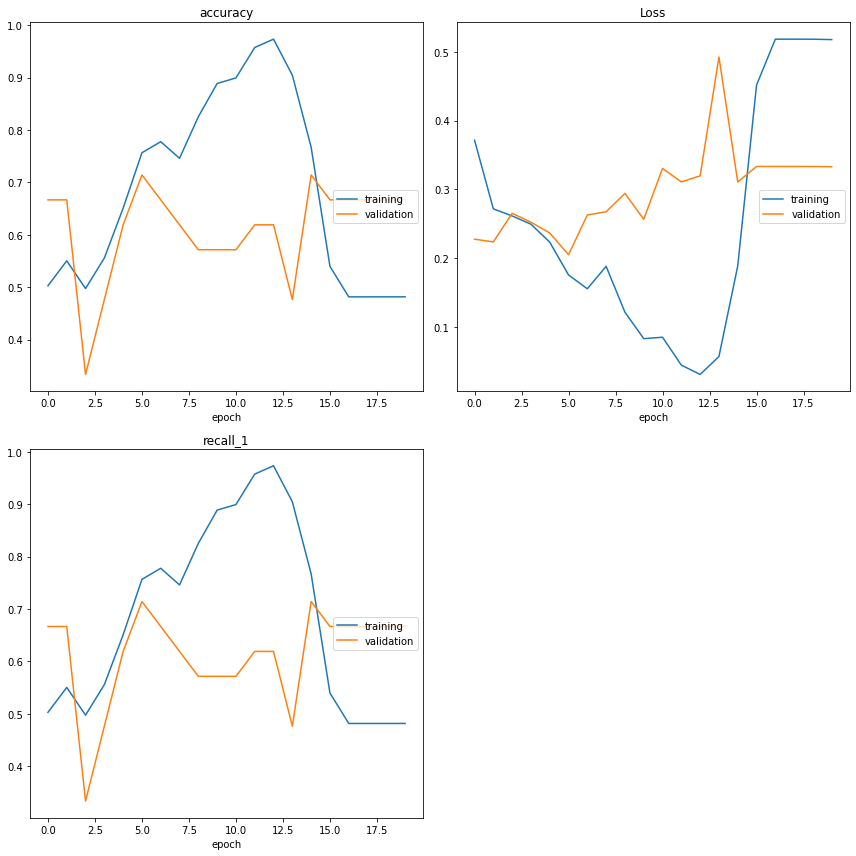

accuracy
	training         	 (min:    0.481, max:    0.974, cur:    0.481)
	validation       	 (min:    0.333, max:    0.714, cur:    0.667)
Loss
	training         	 (min:    0.031, max:    0.518, cur:    0.518)
	validation       	 (min:    0.205, max:    0.492, cur:    0.333)
recall_1
	training         	 (min:    0.481, max:    0.974, cur:    0.481)
	validation       	 (min:    0.333, max:    0.714, cur:    0.667)
19/19 [==============================] - 1s 62ms/step - loss: 0.5177 - accuracy: 0.4815 - recall_1: 0.4815 - val_loss: 0.3329 - val_accuracy: 0.6667 - val_recall_1: 0.6667


In [ ]:
def run_experiment():
    filepath = "best-weights-surveillance-08-12-n1.h5"
    
    # Config callback's
    checkpoint = ModelCheckpoint(
        filepath, save_weights_only=True, save_best_only=True, verbose=1
    )
    plot_loss_1 = PlotLossesCallback()
    wandbr_callbck = WandbCallback()

    wandb.config = {
      "learning_rate": 0.001,
      "epochs": 20,
      "batch_size": BATCH_SIZE
    }

    train_labels_ohe = np_utils.to_categorical(train_labels, 2)
    test_labels_ohe = np_utils.to_categorical(test_labels, 2)

    fight_detection_model = get_fight_detection_model()

    history = fight_detection_model.fit(
        [train_data[0],train_data[1]],
        train_labels_ohe,
        validation_split=0.1,
        epochs=EPOCHS,
        callbacks=[checkpoint, plot_loss_1, wandbr_callbck],        
        batch_size=BATCH_SIZE
    )

    fight_detection_model.load_weights(filepath)
    # _, accuracy = fight_detection_model.evaluate([test_data[0], test_data[1]], test_labels_ohe)
    # print(f"Test accuracy: {round(accuracy * 100, 2)}%")

    return history, fight_detection_model

_, fight_detection_model = run_experiment()

### Inference Test

In [ ]:
def prepare_single_video(frames):
    frames = frames[None, ...]
    frame_mask = np.zeros(shape=(1, MAX_SEQ_LENGTH,), dtype="bool")
    frame_features = np.zeros(shape=(1, MAX_SEQ_LENGTH, NUM_FEATURES), dtype="float32")

    for i, batch in enumerate(frames):
        video_length = batch.shape[0]
        length = min(MAX_SEQ_LENGTH, video_length)
        for j in range(length):
            frame_features[i, j, :] = feature_extractor.predict(batch[None, j, :], verbose=0)
        frame_mask[i, :length] = 1  # 1 = not masked, 0 = masked

    return frame_features, frame_mask


def sequence_prediction(path):
    class_vocab = label_processor.get_vocabulary()
    
    fightText = 'Fight'
    noFightText = 'No Fight'

    frames = load_video(path)
    frame_features, frame_mask = prepare_single_video(frames)
    probabilities = fight_detection_model.predict([frame_features, frame_mask],verbose=0)


    textToAppear = fightText if probabilities[0][0] > probabilities[0][1] else noFightText

    for frame in frames:
      cv2.putText(img=frame, text=textToAppear, org=(30, 40), fontFace=cv2.FONT_HERSHEY_TRIPLEX, fontScale=1, color=(255, 0, 0),thickness=2)
    
    for i in np.argsort(probabilities[0])[::-1]:
        print(f"  {class_vocab[i]}: {probabilities[0][i] * 100:5.2f}%")
    return frames

def sequence_prediction_v2(path):
    class_vocab = label_processor.get_vocabulary()
    
    fightText = 'Fight'
    noFightText = 'No Fight'

    frames = load_video(path)
    old_index = 0
    for index in range(0, len(frames), 5):
      frame_features, frame_mask = prepare_single_video(frames[old_index:index])
      probabilities = fight_detection_model.predict([frame_features, frame_mask], verbose=0, use_multiprocessing=True)

      # print(probabilities)
      textToAppear = "Fight"
      if probabilities[0][0] > probabilities[0][1]:
        textToAppear = f"{fightText} - {probabilities[0][0] * 100:5.2f}%" 
      else:
        textToAppear = f"{fightText} - {probabilities[0][1] * 100:5.2f}%"

      for frame in frames[old_index:index]:
        cv2.putText(
            img=frame,
            fontScale=1,
            thickness=2,
            org=(20, 30),
            text=textToAppear,
            color=(255, 0, 0),
            fontFace=cv2.FONT_HERSHEY_PLAIN
        )
      old_index = index

    return frames

def create_inference_video(video_name, frames_list):
  out = cv2.VideoWriter(
    f"{video_name}.avi", 
    cv2.VideoWriter_fourcc('M','J','P','G'),
    30,
    (299,299)
  )
  
  for i in range(len(test_frames)):
      out.write(test_frames[i])
  out.release()

In [ ]:
fight_detection_model = get_fight_detection_model()
fight_detection_model.load_weights("best-weights-08-12-n1.h5")

OSError: ignored

Test video path: /content/drive/MyDrive/GraduationProject/datasets/final_dataset/fight/fi070.mp4


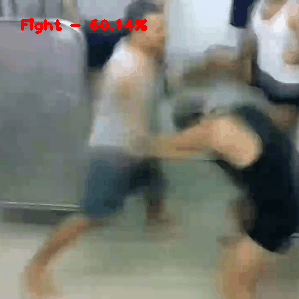

In [ ]:
# This utility is for visualization.
# Referenced from:
# https://www.tensorflow.org/hub/tutorials/action_recognition_with_tf_hub
from IPython.display import Image
def to_gif(images):
    converted_images = images.astype(np.uint8)
    imageio.mimsave("/animation.gif", converted_images, fps=30)

    return Image(open("/animation.gif",'rb').read())

test_video_index = np.random.choice(len(test_df["video_name"].values.tolist())-1)
video_name = test_df['video_name'].tolist()[test_video_index]
class_name = test_df['class'].tolist()[test_video_index]
test_video_path = f"/content/drive/MyDrive/GraduationProject/datasets/final_dataset/{class_name}/{video_name}"
print(f"Test video path: {test_video_path}")
test_frames = sequence_prediction_v2(test_video_path)
to_gif(test_frames)

## Create a inference video

In [ ]:
test_videos_path = list(paths.list_files("/content/drive/MyDrive/GraduationProject/datasets/testing_videos/"))
test_videos_path

['/content/drive/MyDrive/GraduationProject/datasets/testing_videos/CCTV_fight_0008.mpeg',
 '/content/drive/MyDrive/GraduationProject/datasets/testing_videos/CCTV_fight_0013.mpeg',
 '/content/drive/MyDrive/GraduationProject/datasets/testing_videos/CCTV_fight_0009.mpeg',
 '/content/drive/MyDrive/GraduationProject/datasets/testing_videos/CCTV_fight_0012.mpeg',
 '/content/drive/MyDrive/GraduationProject/datasets/testing_videos/CCTV_fight_00014.mpeg',
 '/content/drive/MyDrive/GraduationProject/datasets/testing_videos/weights_16_10_74.h5',
 '/content/drive/MyDrive/GraduationProject/datasets/testing_videos/hockey-test/fi16_xvid.avi',
 '/content/drive/MyDrive/GraduationProject/datasets/testing_videos/hockey-test/fi1_xvid.avi',
 '/content/drive/MyDrive/GraduationProject/datasets/testing_videos/hockey-test/fi42_xvid.avi',
 '/content/drive/MyDrive/GraduationProject/datasets/testing_videos/hockey-test/fi65_xvid.avi',
 '/content/drive/MyDrive/GraduationProject/datasets/testing_videos/hockey-test/fi

In [ ]:
video_path = '/content/drive/MyDrive/GraduationProject/datasets/testing_videos/hockey-test/no237_xvid.avi'
test_frames = sequence_prediction_v2(video_path)
out_name = video_path.split('/')[7].split('.')[0]
out_path = f"inference_{out_name}_124141.avi"
create_inference_video(out_path, test_frames)

In [ ]:
test_videos_path = list(paths.list_files("/content/drive/MyDrive/GraduationProject/datasets/testing_videos/ucf-crime-test"))
# print(f"Test video path: {test_video_path}")
!cd /content/drive/MyDrive/GraduationProject/results-peliculas/
for index, video_path in enumerate(test_videos_path):
  test_frames = sequence_prediction_v2(video_path)
  out_name = video_path.split('/')[7].split('.')[0]
  out_path = f"data/inference_{out_name}_{index}"
  create_inference_video(out_name, test_frames)

print("FINISHED BOY 👍")

FINISHED BOY 👍


# Xception Model in Nails

In [ ]:
#@title
#import necessary libraries
# reference -> https://towardsdatascience.com/xception-from-scratch-using-tensorflow-even-better-than-inception-940fb231ced9
import tensorflow as tf
from tensorflow.keras.layers import Input,Dense,Conv2D,Add
from tensorflow.keras.layers import SeparableConv2D,ReLU
from tensorflow.keras.layers import BatchNormalization,MaxPool2D
from tensorflow.keras.layers import GlobalAvgPool2D
from tensorflow.keras import Model

In [ ]:
#@title
# creating the Conv-Batch Norm block

def conv_bn(x, filters, kernel_size, strides=1):
  x = Conv2D(filters=filters, 
              kernel_size = kernel_size, 
              strides=strides, 
              padding = 'same', 
              use_bias = False)(x)
  x = BatchNormalization()(x)
  return x
# creating separableConv-Batch Norm block

def sep_bn(x, filters, kernel_size, strides=1):
  x = SeparableConv2D(filters=filters, 
                      kernel_size = kernel_size, 
                      strides=strides, 
                      padding = 'same', 
                      use_bias = False)(x)
  x = BatchNormalization()(x)
  return x

In [ ]:
#@title
# entry flow

def entry_flow(x):  
  x = conv_bn(x, filters =32, kernel_size =3, strides=2)
  x = ReLU()(x)
  x = conv_bn(x, filters =64, kernel_size =3, strides=1)
  tensor = ReLU()(x)
  
  x = sep_bn(tensor, filters = 128, kernel_size =3)
  x = ReLU()(x)
  x = sep_bn(x, filters = 128, kernel_size =3)
  x = MaxPool2D(pool_size=3, strides=2, padding = 'same')(x)
  
  tensor = conv_bn(tensor, filters=128, kernel_size = 1,strides=2)
  x = Add()([tensor,x])
  
  x = ReLU()(x)
  x = sep_bn(x, filters =256, kernel_size=3)
  x = ReLU()(x)
  x = sep_bn(x, filters =256, kernel_size=3)
  x = MaxPool2D(pool_size=3, strides=2, padding = 'same')(x)
  
  tensor = conv_bn(tensor, filters=256, kernel_size = 1,strides=2)
  x = Add()([tensor,x])
  
  x = ReLU()(x)
  x = sep_bn(x, filters =728, kernel_size=3)
  x = ReLU()(x)
  x = sep_bn(x, filters =728, kernel_size=3)
  x = MaxPool2D(pool_size=3, strides=2, padding = 'same')(x)
  
  tensor = conv_bn(tensor, filters=728, kernel_size = 1,strides=2)
  x = Add()([tensor,x])
  return x

# middle flow

def middle_flow(tensor):
    
  for _ in range(8):
      x = ReLU()(tensor)
      x = sep_bn(x, filters = 728, kernel_size = 3)
      x = ReLU()(x)
      x = sep_bn(x, filters = 728, kernel_size = 3)
      x = ReLU()(x)
      x = sep_bn(x, filters = 728, kernel_size = 3)
      x = ReLU()(x)
      tensor = Add()([tensor,x])
      
  return tensor
# exit flow

def exit_flow(tensor):
  x = ReLU()(tensor)
  x = sep_bn(x, filters = 728,  kernel_size=3)
  x = ReLU()(x)
  x = sep_bn(x, filters = 1024,  kernel_size=3)
  x = MaxPool2D(pool_size = 3, strides = 2, padding ='same')(x)
  
  tensor = conv_bn(tensor, filters =1024, kernel_size=1, strides =2)
  x = Add()([tensor,x])
  
  x = sep_bn(x, filters = 1536,  kernel_size=3)
  x = ReLU()(x)
  x = sep_bn(x, filters = 2048,  kernel_size=3)
  x = GlobalAvgPool2D()(x)
  
  x = Dense (units = 1000, activation = 'softmax')(x)
  return x


In [ ]:
#@title
# model code

input = Input(shape = (299,299,3))
x = entry_flow(input)
x = middle_flow(x)
output = exit_flow(x)

model = Model (inputs=input, outputs=output)
model.summary()


In [ ]:
#@title
from keras.utils.vis_utils import plot_model
plot_model(model, to_file='model_plot.png', show_shapes=True, show_layer_names=True)

In [ ]:
#@title


In [ ]:
#@title


In [ ]:
#@title
# Utility for running experiments.
def run_experiment():
    filepath = "/tmp/video_classifier"
    checkpoint = keras.callbacks.ModelCheckpoint(
        filepath, save_weights_only=True, save_best_only=True, verbose=1
    )

    seq_model = get_sequence_model()
    history = seq_model.fit(
        [train_data[0], train_data[1]],
        train_labels,
        validation_split=0.3,
        epochs=EPOCHS,
        callbacks=[checkpoint],
    )

    seq_model.load_weights(filepath)
    _, accuracy = seq_model.evaluate([test_data[0], test_data[1]], test_labels)
    print(f"Test accuracy: {round(accuracy * 100, 2)}%")

    return history, seq_model


_, sequence_model = run_experiment()